# Task 1: Multi-Class Benchmark Classification Pipeline
**Curriculum Reference:** DT-2026-NKPSG  
**Focus:** Exploratory Data Analysis, Data Normalization, Multi-Class Model Benchmarking  

---

## 1. Objective
End-to-end multi-class classification benchmark on the Iris dataset comparing two models:
- **Logistic Regression:** Linear, parametric probabilistic classifier.
- **Decision Tree Classifier:** Non-linear, non-parametric tree model with orthogonal splits.

### Evaluation Metrics
- **Accuracy:** Overall proportion of correct predictions across all classes.
- **Precision (Weighted):** Correct positive predictions weighted by class support.
- **Recall (Weighted):** True positive rate weighted by class support.
- **F1-Score (Weighted):** Harmonic mean of precision and recall.


## 2. Setup & Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120


## 3. Data Ingestion & Inspection

In [2]:
data_path = os.path.join("..", "data", "iris.csv")
df = pd.read_csv(data_path)

print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nMissing values:")
print(df.isnull().sum())
df.head(10)


Dataset shape: 150 rows, 5 columns

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


### 3.1 Summary Statistics

In [3]:
display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


## 4. Exploratory Data Analysis
Feature distributions and bivariate separation across target classes (*setosa*, *versicolor*, *virginica*).


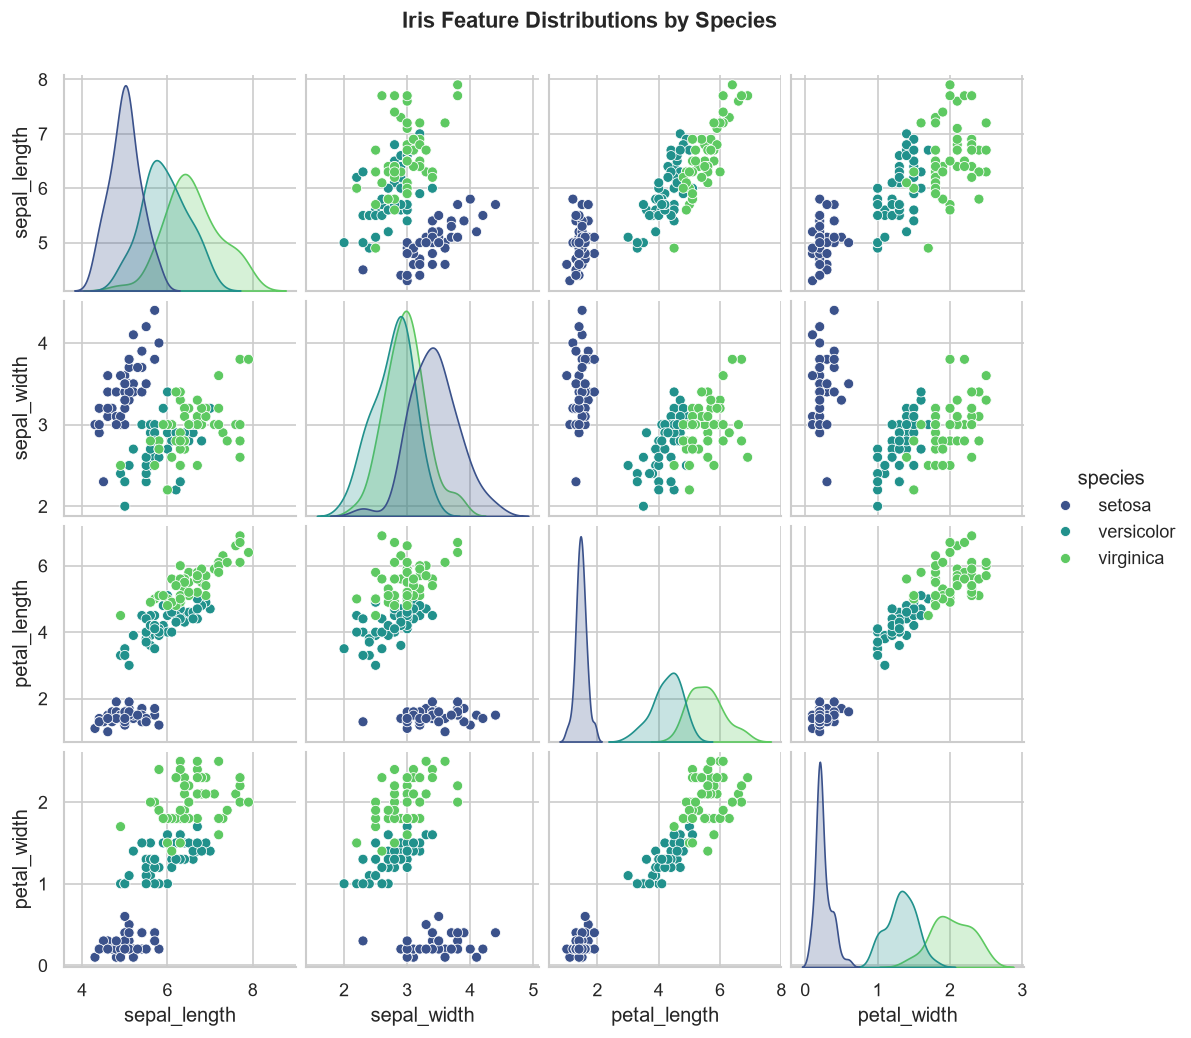

In [4]:
pairplot = sns.pairplot(df, hue="species", palette="viridis", diag_kind="kde", height=2.2)
pairplot.fig.subplots_adjust(top=0.92)
pairplot.fig.suptitle("Iris Feature Distributions by Species", fontsize=13, weight="bold")
plt.show()


### 4.1 Correlation Matrix

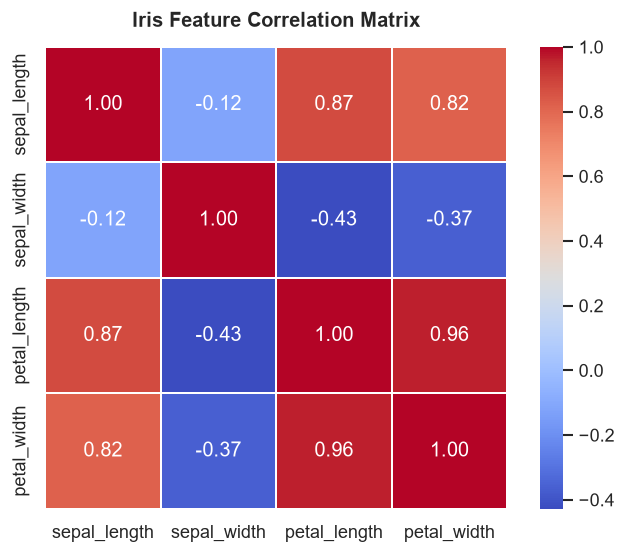

In [5]:
plt.figure(figsize=(7, 5))
numeric_cols = df.drop(columns=["species"])
corr = numeric_cols.corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=1, square=True)
plt.title("Iris Feature Correlation Matrix", fontsize=12, weight="bold", pad=12)
plt.show()


## 5. Preprocessing & Train/Test Split
- Target labels encoded to integers (0, 1, 2).
- Stratified 80/20 train/test split (`random_state=42`).
- Standardize features using `StandardScaler` (zero mean, unit variance).


In [6]:
X = df.drop(columns=["species"]).values
y_raw = df["species"].values

le = LabelEncoder()
y = le.fit_transform(y_raw)
class_names = le.classes_

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train set: {X_train_scaled.shape[0]} samples")
print(f"Test set:  {X_test_scaled.shape[0]} samples")
print("Target classes:", dict(enumerate(class_names)))


Train set: 120 samples
Test set:  30 samples
Target classes: {0: 'setosa', 1: 'versicolor', 2: 'virginica'}


## 6. Model Training & Evaluation
Train both models and evaluate performance on the holdout test set.


In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=200, random_state=42),
    "Decision Tree Classifier": DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=42),
}

benchmark_results = {}
reports = {}
confusion_matrices = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    
    benchmark_results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted"),
        "Recall": recall_score(y_test, y_pred, average="weighted"),
        "F1-Score": f1_score(y_test, y_pred, average="weighted"),
        "Predictions": y_pred,
    }
    reports[name] = classification_report(y_test, y_pred, target_names=class_names)
    confusion_matrices[name] = confusion_matrix(y_test, y_pred)

for name in models:
    print(f"=== {name} Classification Report ===")
    print(reports[name])


=== Logistic Regression Classification Report ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

=== Decision Tree Classifier Classification Report ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



## 7. Confusion Matrix Heatmaps

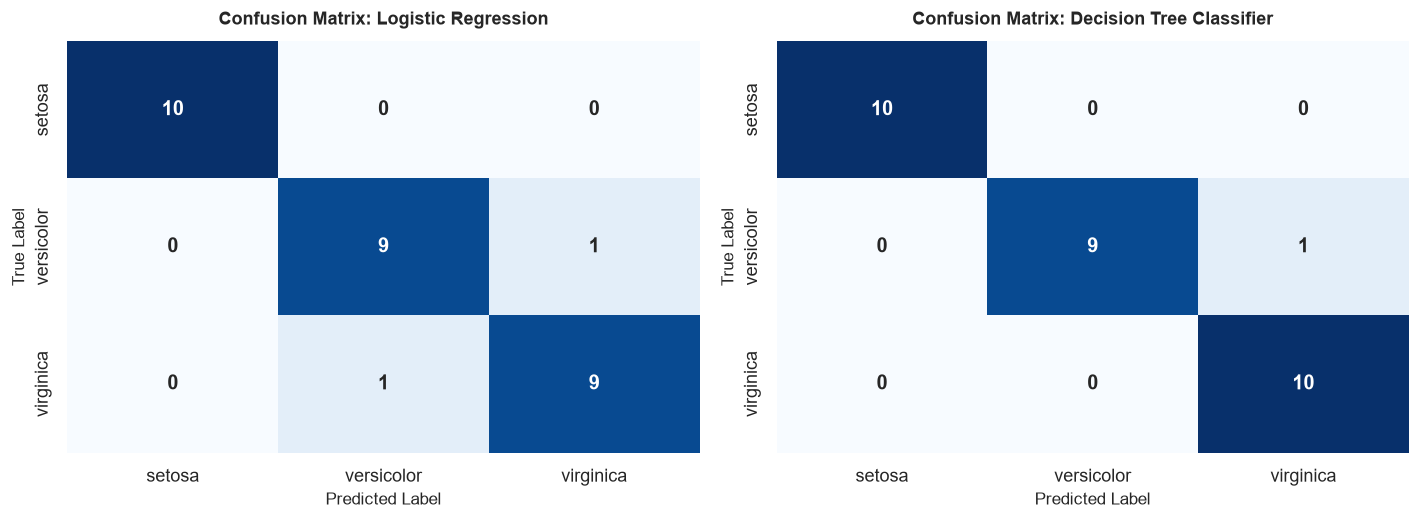

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, (name, cm) in zip(axes, confusion_matrices.items()):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        cbar=False,
        ax=ax,
        annot_kws={"size": 12, "weight": "bold"},
    )
    ax.set_title(f"Confusion Matrix: {name}", fontsize=11, weight="bold", pad=10)
    ax.set_xlabel("Predicted Label", fontsize=10)
    ax.set_ylabel("True Label", fontsize=10)

plt.tight_layout()
plt.show()


## 8. Decision Boundary Plots
2D projection of decision boundaries using the two primary discriminative features: Petal Length and Petal Width.


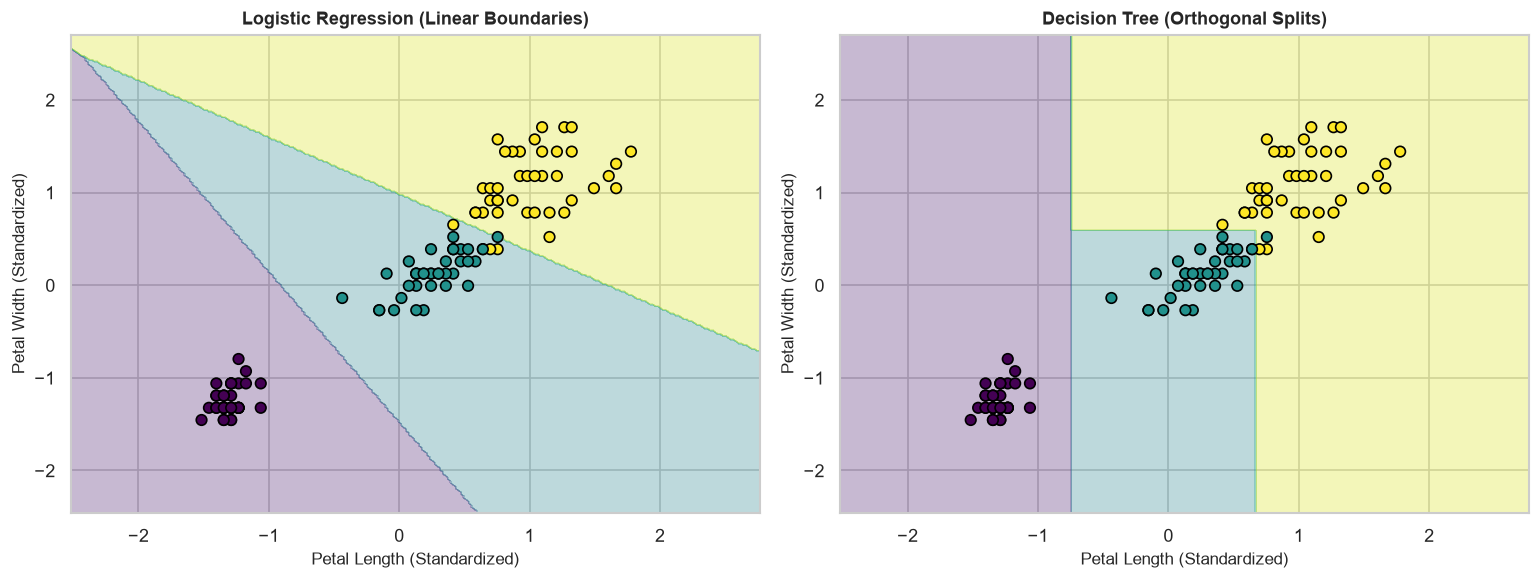

In [9]:
X_2d = df[["petal_length", "petal_width"]].values
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y, test_size=0.20, random_state=42, stratify=y
)

scaler_2d = StandardScaler()
X_train_2d_s = scaler_2d.fit_transform(X_train_2d)

lr_2d = LogisticRegression(max_iter=200, random_state=42)
dt_2d = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=42)

lr_2d.fit(X_train_2d_s, y_train_2d)
dt_2d.fit(X_train_2d_s, y_train_2d)

x_min, x_max = X_train_2d_s[:, 0].min() - 1, X_train_2d_s[:, 0].max() + 1
y_min, y_max = X_train_2d_s[:, 1].min() - 1, X_train_2d_s[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
models_2d = [
    ("Logistic Regression (Linear Boundaries)", lr_2d),
    ("Decision Tree (Orthogonal Splits)", dt_2d),
]

for ax, (title, clf) in zip(axes, models_2d):
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
    ax.scatter(
        X_train_2d_s[:, 0],
        X_train_2d_s[:, 1],
        c=y_train_2d,
        cmap="viridis",
        edgecolor="black",
        s=40,
    )
    ax.set_title(title, fontsize=11, weight="bold")
    ax.set_xlabel("Petal Length (Standardized)", fontsize=10)
    ax.set_ylabel("Petal Width (Standardized)", fontsize=10)

plt.tight_layout()
plt.show()


## 9. Benchmark Summary & Observations

In [10]:
summary_rows = []
for name, metrics in benchmark_results.items():
    summary_rows.append({
        "Model": name,
        "Accuracy": f"{metrics['Accuracy'] * 100:.2f}%",
        "Precision (Weighted)": f"{metrics['Precision'] * 100:.2f}%",
        "Recall (Weighted)": f"{metrics['Recall'] * 100:.2f}%",
        "F1-Score (Weighted)": f"{metrics['F1-Score'] * 100:.2f}%",
    })

summary_table = pd.DataFrame(summary_rows)
display(summary_table)


,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted)
0,Logistic Regression,93.33%,93.33%,93.33%,93.33%
1,Decision Tree Classifier,96.67%,96.97%,96.67%,96.66%


### Observations
- **Class Separability:** Setosa is linearly separable from the other two species using petal dimensions alone.
- **Model Comparison:** 
  - Logistic Regression achieved **93.33%** test accuracy with linear decision boundaries.
  - Decision Tree achieved **96.67%** test accuracy with hierarchical orthogonal splits.
- **Generalization:** Both models perform well on the test split without severe overfitting under depth/regularization constraints.
